# Edge Sense: efficient sensor models

**Question:** How much accuracy and robustness survive model compression, and does simulated pretraining help when real labels are scarce?

A nine-channel smartphone activity-recognition pipeline compares a teacher, small students, distillation, partial dynamic INT8, and controlled simulation-to-real experiments. [Project guide](../projects/01-edge-sense/README.md) · [Protocol](../docs/EXPERIMENTS.md)

## How to run
Run all cells from the repository root or this directory. Install the notebook extra with `uv pip install -e '.[notebooks]'` and select that Python environment. The report sections need only committed JSON measurements. They do not need checkpoints, API keys, downloads, or Apple hardware. Edge Sense and Edge Pilot also have an optional local inference section that needs generated checkpoints and validation arrays. Saved study outputs and fresh local measurements are labeled separately.

## What the model actually sees

A phone has an accelerometer, which measures acceleration, and a gyroscope, which measures rotation. The dataset separates acceleration caused by body movement from total acceleration. Each signal has x, y, and z axes, giving nine channels in total.

One input contains 128 readings per channel at 50 readings per second: about 2.56 seconds of motion. Its shape is `(9, 128)`. A batch adds an outer dimension, so 64 windows have shape `(64, 9, 128)`. The answer is one of six activities: walking, walking upstairs, walking downstairs, sitting, standing, or lying down.

A convolutional network slides small learned filters across time to detect patterns such as repeated steps or changes in rotation. It then combines those patterns into six scores. Softmax turns the scores into probabilities that sum to one. These probabilities are useful for comparing outputs, but they should not be read as guaranteed confidence.

## Why there are several versions of the network

The **teacher** is the larger network. A **student** has fewer weights and is cheaper to store. The ordinary student learns from activity labels. The **distilled** student also learns from the teacher’s output scores: for example, which two activities the teacher finds similar.

The robust training variant exposes the model to sensor corruption during training. The accelerometer-only variant removes the gyroscope input to show the cost of losing that information. Dynamic INT8 converts selected linear layers to a smaller integer representation; it does not convert the whole network to integer math. That variant stays on the CPU path. The GPU example uses the floating-point distilled checkpoint.

## Why split by person instead of by random window

Windows from the same person share movement style, sensor placement, and often overlapping signal samples. If nearby windows land in both training and test sets, the test can become too easy. Here, entire people are assigned to different splits.

Training fits the weights and normalization constants. Validation helps choose models and settings. The official test subjects are used only for the final report. The next cell checks subject separation using the recorded dataset catalog and prints the exact split sizes.

## Reading the tradeoff plot

Each point is one model family averaged over three training seeds. Moving upward means better test macro F1. Moving left means a smaller serialized weight file. Error bars show how much the three runs differed; they are not a promise about future users.

The teacher is a useful quality reference. The practical question is whether the small model loses little enough quality to justify its smaller file. File size is not the same as total memory use: the runtime, input tensors, and temporary intermediate tensors also take memory. The table reports CPU timings separately because a smaller file does not guarantee faster execution.

## What simulation adds, and what it cannot replace

The simulator generates motion-like signals with controlled frequency, amplitude, and noise. Randomizing these settings makes the synthetic training data less uniform. It still does not reproduce every detail of a real phone recording.

The synthetic-only conditions ask whether those signals transfer directly to real people. The two few-shot conditions ask a narrower question: with only 480 labeled real windows available, does synthetic pretraining help compared with starting from scratch? Keeping the real-label budget equal is what makes that comparison useful. In this run, it did not help on average.

## What export parity checks

A trained PyTorch model is not automatically ready to call from a Swift app. Core ML export changes its representation, and weight compression changes it again. A parity check feeds the same inputs through both versions and compares their answers.

Top-1 agreement asks whether the most likely activity stayed the same. Probability differences catch smaller numerical changes that a label-only check could miss. The native Swift check verifies another part of the path: loading and calling the exported model outside Python. These checks establish consistent outputs for the tested inputs; they do not measure battery life or Neural Engine placement.

In [1]:
from pathlib import Path
import hashlib
import json
import statistics
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports/results.json").is_file())
RESULTS_PATH = ROOT / "reports/results.json"
r = json.loads(RESULTS_PATH.read_text())
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
def table(headers, rows):
    def cell(v):
        return str(v).replace("|", " / ").replace("\n", " ")
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"] * len(headers)) + " |\n" + "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)))
print("Evidence:", RESULTS_PATH.relative_to(ROOT))
print("SHA256:", hashlib.sha256(RESULTS_PATH.read_bytes()).hexdigest())
print("This notebook reanalyzes saved measurements; it does not rerun training or download data.")

Evidence: reports/results.json
SHA256: b382e4a91a7e8103fa6ab03709309848592cd80b8a4ee3c777e6e82ce588636d
This notebook reanalyzes saved measurements; it does not rerun training or download data.


## Data and experimental controls
UCI HAR uses 128-sample windows at 50 Hz. Body acceleration, gyroscope, and total acceleration contribute three channels each. Training normalization uses training data only. Subjects are disjoint; the official test set remains untouched during selection. Procedural sensor signals are explicitly synthetic.

In [2]:
manifest = json.loads((ROOT / "reports/data_manifest.json").read_text())
# The recorded catalog observation preserves split counts and subject identities.
catalog = r["agent_examples"]["intent-router-gyro"]["trace"][0]["observation"]
table(["Split", "Windows", "Subjects"], [(k, v["rows"], ", ".join(map(str, v["subjects"]))) for k, v in catalog["splits"].items()])
subjects = {k: set(v["subjects"]) for k, v in catalog["splits"].items()}
assert all(not subjects[a] & subjects[b] for a, b in [("train", "val"), ("train", "test"), ("val", "test")])
assert r["test"]["used_for_selection"] is False
print("Subject separation and test-selection exclusion verified.")

| Split | Windows | Subjects |
| --- | --- | --- |
| train | 5970 | 1, 3, 6, 7, 8, 11, 14, 16, 17, 21, 22, 23, 25, 27, 28, 29, 30 |
| test | 2947 | 2, 4, 9, 10, 12, 13, 18, 20, 24 |
| val | 1382 | 5, 15, 19, 26 |

Subject separation and test-selection exclusion verified.


## Measured accuracy, size, and latency
Each main candidate has three training seeds. Error bars are sample standard deviation, not confidence intervals. Storage measures serialized state rather than peak RAM. CPU timing is environment-specific; development measurements had concurrent load.

| Model | Test macro F1 | Seed SD | KiB | CPU p95 ms |
| --- | --- | --- | --- | --- |
| teacher | 0.9280 | 0.0034 | 484.2 | 0.889 |
| student | 0.9222 | 0.0077 | 59.8 | 0.106 |
| distilled | 0.9234 | 0.0083 | 59.8 | 0.199 |
| robust_distilled | 0.9194 | 0.0014 | 59.8 | 0.121 |
| accel_only | 0.8021 | 0.0048 | 57.0 | 0.117 |
| synthetic_fixed | 0.3610 | 0.0538 | 59.8 | 0.110 |
| synthetic_randomized | 0.5161 | 0.0521 | 59.8 | 0.112 |
| fewshot_scratch | 0.8853 | 0.0092 | 59.8 | 0.120 |
| sim_to_real | 0.8780 | 0.0169 | 59.8 | 0.116 |
| dynamic_int8 | 0.9237 | 0.0086 | 33.1 | 0.194 |

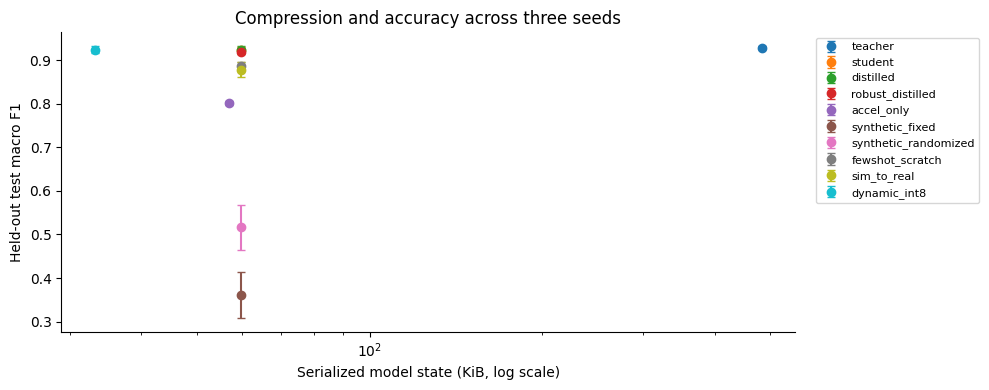

In [3]:
a = r["aggregates"]
table(["Model", "Test macro F1", "Seed SD", "KiB", "CPU p95 ms"], [(x["name"], f'{x["test_f1_mean"]:.4f}', f'{x["test_f1_std"]:.4f}', f'{x["bytes"]/1024:.1f}', f'{x["p95_ms_median"]:.3f}') for x in a])
fig, ax = plt.subplots()
for x in a:
    ax.errorbar(x["bytes"]/1024, x["test_f1_mean"], yerr=x["test_f1_std"], fmt="o", capsize=3, label=x["name"])
ax.set(xscale="log", xlabel="Serialized model state (KiB, log scale)", ylabel="Held-out test macro F1", title="Compression and accuracy across three seeds")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## Equal-label-budget simulation-to-real comparison
Both few-shot conditions use the same 480 real training windows. Synthetic-only models expose the domain gap. The saved results show a negative transfer result; synthetic pretraining is not presented as an improvement.

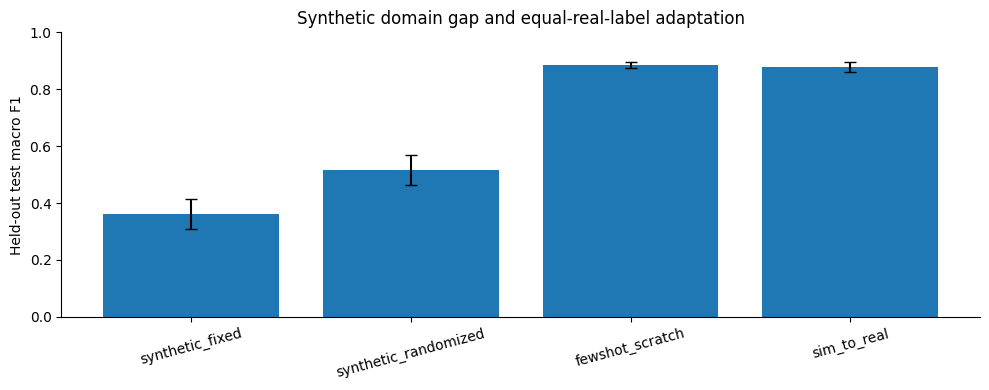

Simulation pretraining difference: -0.73 percentage points (descriptive seed mean).
Supervised student state reduction: 8.10×


In [4]:
by_name = {x["name"]: x for x in a}
names = ["synthetic_fixed", "synthetic_randomized", "fewshot_scratch", "sim_to_real"]
fig, ax = plt.subplots()
ax.bar(names, [by_name[k]["test_f1_mean"] for k in names], yerr=[by_name[k]["test_f1_std"] for k in names], capsize=4)
ax.set(ylabel="Held-out test macro F1", ylim=(0, 1), title="Synthetic domain gap and equal-real-label adaptation")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
delta = 100*(by_name["sim_to_real"]["test_f1_mean"]-by_name["fewshot_scratch"]["test_f1_mean"])
print(f"Simulation pretraining difference: {delta:+.2f} percentage points (descriptive seed mean).")
print(f"Supervised student state reduction: {by_name['teacher']['bytes']/by_name['student']['bytes']:.2f}×")

## Deployment evidence and limits
Core ML uses weight-only INT8 with floating activations. Export agreement is measured over validation data. Python CPU_ONLY timing is not an Apple Neural Engine benchmark. A native Swift parity check adds a separate execution check.

In [5]:
table(["Export", "Package KiB", "Top-1 agreement", "CPU p95 ms"], [(x["variant"], f'{x["package_bytes"]/1024:.1f}', x["pytorch_top1_agreement"], f'{x["p95_ms"]:.3f}') for x in r["apple"]["variants"]])
print("Native probability parity passed:", r["native"]["passed"])
print("Independent HAR70+ probe limitation:", r["external"]["limits"])

| Export | Package KiB | Top-1 agreement | CPU p95 ms |
| --- | --- | --- | --- |
| float32 | 66.6 | 1.0 | 0.057 |
| weight_int8 | 28.7 | 1.0 | 0.059 |

Native probability parity passed: True
Independent HAR70+ probe limitation: Mismatched population, placement, preprocessing, absent gyro; descriptive only.


## Interpretation and reproduction
The small models retain much of the teacher accuracy, while modality loss remains a meaningful failure mode. The independent HAR70+ probe changes population, placement, preprocessing, and sensor availability; it is a domain-shift probe rather than a comparable benchmark. Three seeds do not establish statistical significance.

Rebuild with `python scripts/train_study.py --config configs/overnight.yaml`, followed by held-out evaluation as described in [reproduction instructions](../docs/REPRODUCING.md). See [data attribution](../docs/DATA_CARD.md) and the [model card](../docs/MODEL_CARD.md).

## Try inference on this machine

This optional section loads a **floating-point** checkpoint and real validation windows. `auto` selects CUDA when available, then Apple MPS, then CPU. Set `DEVICE = "cuda"`, `"mps"`, or `"cpu"` to request one explicitly. An unavailable explicit choice raises an error rather than silently reporting CPU work as GPU work.

Checkpoints and sensor arrays are not stored in Git. If they are missing, the cell prints the commands needed to generate them and skips the benchmark. It does not download data or train anything on its own. The plots above still work without these files.

The benchmark keeps a batch on the device, warms up the network, then waits for device work to finish around each timed call. Input transfers and loading are outside the timer. The result is **batch forward duration**, not end-to-end application latency. Use batch size 1 to measure single-window calls, or 64 to explore throughput. A GPU can be slower for a network this small.

The returned probabilities are compared against the same floating model on CPU. Small numerical differences are expected. This does not compare a floating GPU model against the CPU-only dynamic INT8 implementation.

Timing details: [CUDA synchronization](https://docs.pytorch.org/docs/stable/generated/torch.cuda.synchronize.html) and [MPS synchronization](https://docs.pytorch.org/docs/stable/generated/torch.mps.synchronize.html).

In [6]:
import torch
from edge_agent_lab.inference import resolve_device, run_inference
from edge_agent_lab.models import load_model
from edge_agent_lab.data import ensure_data, load_split
import numpy as np

DEVICE = "auto"  # Or explicitly request "cuda", "mps", or "cpu".
BATCH_SIZE = 64   # Set to 1 for single-window timing.
CHECKPOINT = ROOT / "artifacts/edge/seed-7/distilled/model.pt"
DATA_ROOT = ROOT / "data/har"
print("Available:", {"cuda": torch.cuda.is_available(), "mps": torch.backends.mps.is_available()})
print("Selected device:", resolve_device(DEVICE))
if not CHECKPOINT.is_file() or not (DATA_ROOT / "val.npz").is_file():
    print("Skipped: this checkout has no local checkpoint or validation arrays.")
    print("From the repository root: edge-lab prepare")
    print("Then: edge-lab train --seeds 7 --epochs 40 --compact")
    print("For the search checkpoint also run: python scripts/run_search.py")
else:
    ensure_data(DATA_ROOT)  # Check cached file hashes before loading.
    model = load_model(CHECKPOINT)
    windows = load_split(DATA_ROOT, "val").x[:256]
    # This fixed subset checks execution and parity, not validation-wide accuracy.
    current, timing = run_inference(model, windows, DEVICE, BATCH_SIZE, repeats=20)
    reference, cpu_timing = run_inference(model, windows, "cpu", BATCH_SIZE, repeats=20)
    table(["Measurement", "Selected device", "CPU reference"], [
        ("Device", timing["device"], cpu_timing["device"]),
        ("Batch size", timing["batch_size"], cpu_timing["batch_size"]),
        ("Batch p50 ms", round(timing["batch_p50_ms"], 3), round(cpu_timing["batch_p50_ms"], 3)),
        ("Batch p95 ms", round(timing["batch_p95_ms"], 3), round(cpu_timing["batch_p95_ms"], 3)),
        ("Windows/sec at p50", round(timing["windows_per_second_at_p50"]), round(cpu_timing["windows_per_second_at_p50"])),
    ])
    agreement = float((current.argmax(1) == reference.argmax(1)).mean())
    print("Top-1 agreement with CPU:", agreement)
    print("Maximum probability difference:", float(np.abs(current-reference).max()))
    print("Hardware:", timing["hardware"], "| PyTorch:", timing["torch"])
    print("Timing scope:", timing["timing_scope"])
    print("These are fresh local measurements, separate from the saved study.")

Available: {'cuda': False, 'mps': True}
Selected device: mps


| Measurement | Selected device | CPU reference |
| --- | --- | --- |
| Device | mps | cpu |
| Batch size | 64 | 64 |
| Batch p50 ms | 1.357 | 3.096 |
| Batch p95 ms | 1.854 | 3.68 |
| Windows/sec at p50 | 47156 | 20670 |

Top-1 agreement with CPU: 1.0
Maximum probability difference: 9.238719940185547e-07
Hardware: Apple GPU (MPS) | PyTorch: 2.2.2
Timing scope: resident-input forward; includes dispatch and synchronization; no transfers
These are fresh local measurements, separate from the saved study.


To evaluate all validation windows and save the result outside the notebook:

```bash
edge-infer --checkpoint artifacts/edge/seed-7/distilled/model.pt --device auto --batch-size 64
```

Use `--device cuda` on an NVIDIA machine with a compatible CUDA-enabled PyTorch installation. The default dependency pin is PyTorch 2.2.2, which may not support newer GPU architectures; a different CUDA/PyTorch environment needs its own compatibility checks and should be recorded as a separate environment. Do not replace the pinned study dependencies just to view the saved results.

The command saves fresh results to `artifacts/inference/latest.json`. It does not overwrite `reports/results.json`, retrain the model, or change which candidate was selected.

## Pruning an already trained network

The earlier comparisons use distillation and quantization. **Distillation** changes how a smaller network learns from a teacher. **Quantization** stores or computes selected weights using fewer bits. **Pruning** removes connections or channels from a network that already has trained weights. These methods solve related problems, but they are different operations.

The added experiment starts from the same seed-7 floating distilled student for every candidate. It compares the original model, a dense model with extra fine-tuning, two magnitude-pruned models, and two physically smaller channel-pruned models. The extra dense run is a control: otherwise an apparent pruning benefit could simply come from giving a model more training.

Results below come from `reports/pruning.json`, separate from the original three-seed study. This added comparison uses one checkpoint and one fine-tuning seed.

In [7]:
pruning = json.loads((ROOT / "reports/pruning.json").read_text())
pruned = {c["name"]: c for c in pruning["candidates"]}
print("Source checkpoint SHA256:", pruning["source_sha256"])
print("Fine-tuning seed:", pruning["seed"], "| maximum epochs:", pruning["fine_tuning_epochs"])
print("Selection:", pruning["selection_rule"])
assert pruning["test_used_for_selection"] is False

Source checkpoint SHA256: d207e077aa5751f87c518590e3afdc8e680bd71220900ee687217bbe61c1f0ab
Fine-tuning seed: 7 | maximum epochs: 5
Selection: smallest state within 0.02 validation macro F1 of original dense source


### Zeroing weights versus removing channels

For **global magnitude pruning**, PyTorch collects the convolution and linear-layer weights, ranks them by absolute value, and masks the smallest 50% or 70%. A mask multiplies selected weights by zero. It stays attached during fine-tuning, so optimizer steps cannot reactivate those connections. `prune.remove` then writes the masked values into ordinary weights and removes the hooks. This keeps the model compatible with the existing checkpoint loader.

There is a catch: a dense tensor containing zeros has the same dimensions as before. Standard dense kernels still process it, and the checkpoint still stores it densely. More zeros do not automatically mean a smaller model or faster inference. A sparse runtime would be a separate implementation and benchmark.

For **channel pruning**, the code ranks output channels within each layer by L1 weight magnitude, keeps a subset, and constructs a narrower network. It copies matching convolution inputs and outputs, BatchNorm statistics, flattened features, and hidden units. The six activity outputs stay intact. The 75%-width and 50%-width labels refer to the fraction of width **kept**, not the fraction removed.

This is explicit slicing for this small sequential network. It rejects the fusion architecture rather than pretending the same indices work through every graph. Tests compare the compact output against a full-sized reference with the removed activations masked, which catches mistakes in channel dependencies.

| Candidate | Parameters | Zero weights | Checkpoint KiB | Val before tuning | Val after tuning | Test F1 |
| --- | --- | --- | --- | --- | --- | --- |
| dense_original | 13662 | 0% | 59.6 | 0.9602 | 0.9602 | 0.9139 |
| dense_finetuned | 13662 | 0% | 59.6 | 0.9602 | 0.9602 | 0.9139 |
| magnitude_50 | 13662 | 50% | 59.6 | 0.9485 | 0.9553 | 0.9209 |
| magnitude_70 | 13662 | 70% | 59.6 | 0.7342 | 0.9531 | 0.8832 |
| channels_75pct | 7980 | 0% | 37.7 | 0.5532 | 0.9672 | 0.8997 |
| channels_50pct | 3810 | 0% | 20.8 | 0.2901 | 0.9450 | 0.8969 |

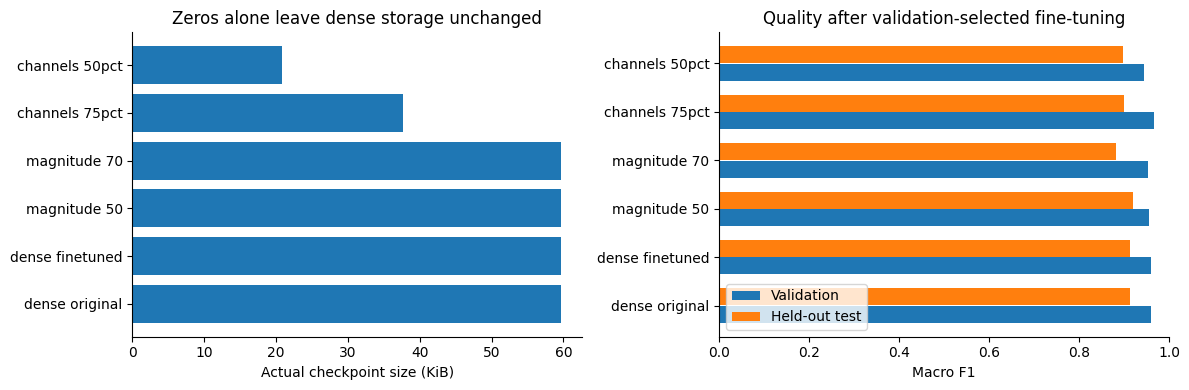

In [8]:
table(["Candidate", "Parameters", "Zero weights", "Checkpoint KiB", "Val before tuning", "Val after tuning", "Test F1"], [
    (c["name"], c["parameters"], f'{c["weight_sparsity"]:.0%}', f'{c["checkpoint_bytes"]/1024:.1f}',
     f'{c["before_finetuning_validation"]["macro_f1"]:.4f}', f'{c["validation"]["macro_f1"]:.4f}', f'{c["test"]["macro_f1"]:.4f}')
    for c in pruning["candidates"]])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = [c["name"].replace("_", " ") for c in pruning["candidates"]]
axes[0].barh(labels, [c["checkpoint_bytes"]/1024 for c in pruning["candidates"]])
axes[0].set(xlabel="Actual checkpoint size (KiB)", title="Zeros alone leave dense storage unchanged")
import numpy as np
x = np.arange(len(labels))
axes[1].barh(x-.18, [c["validation"]["macro_f1"] for c in pruning["candidates"]], height=.35, label="Validation")
axes[1].barh(x+.18, [c["test"]["macro_f1"] for c in pruning["candidates"]], height=.35, label="Held-out test")
axes[1].set(yticks=x, yticklabels=labels, xlim=(0, 1), xlabel="Macro F1", title="Quality after validation-selected fine-tuning")
axes[1].legend(loc="lower left"); plt.tight_layout(); plt.show()

### Recovery training and timing

The compact models can lose a lot of accuracy immediately after channels are removed. Fine-tuning lets the remaining weights adapt to the missing channels. Every fine-tuned candidate gets the same maximum five epochs, learning rate, training subjects, and seed. Validation selects the best epoch, including the initial state as an option. The test set is loaded after those choices and the winner are fixed.

The timing table uses three interleaved rounds after training, with a shuffled candidate order each round. Values are medians of the per-round p95 measurements; CPU ranges show the spread between rounds. This reduces ordering effects but does not make a short local timing run a universal speed claim. The floating sparse models still use dense kernels. Batch-one CPU latency and batch-64 device duration are different measurements.

In [9]:
devices = list(pruning["candidates"][0]["device_batch64"])
table(["Candidate", "CPU batch-1 p95 ms", "CPU p95 round range"] + [f"{d} batch-64 p95 ms" for d in devices], [
    (c["name"], f'{c["cpu_batch1"]["p95_ms"]:.3f}',
     "–".join(f"{v:.3f}" for v in c["cpu_batch1"]["p95_round_range_ms"])) +
    tuple(f'{c["device_batch64"][d]["batch_p95_ms"]:.3f}' for d in devices)
    for c in pruning["candidates"]])
original, compact = pruned["dense_original"], pruned["channels_50pct"]
print(f"Half-width checkpoint reduction: {original['checkpoint_bytes']/compact['checkpoint_bytes']:.2f}×")
print(f"Half-width parameter reduction: {original['parameters']/compact['parameters']:.2f}×")
print(f"Half-width held-out F1 change: {100*(compact['test']['macro_f1']-original['test']['macro_f1']):+.2f} percentage points")

| Candidate | CPU batch-1 p95 ms | CPU p95 round range | cpu batch-64 p95 ms | mps batch-64 p95 ms |
| --- | --- | --- | --- | --- |
| dense_original | 0.088 | 0.087–0.088 | 2.204 | 1.084 |
| dense_finetuned | 0.088 | 0.087–0.088 | 2.232 | 1.079 |
| magnitude_50 | 0.089 | 0.088–0.190 | 2.242 | 1.081 |
| magnitude_70 | 0.088 | 0.088–0.128 | 2.198 | 1.110 |
| channels_75pct | 0.087 | 0.087–0.089 | 1.736 | 1.095 |
| channels_50pct | 0.087 | 0.087–0.087 | 1.348 | 1.026 |

Half-width checkpoint reduction: 2.87×
Half-width parameter reduction: 3.59×
Half-width held-out F1 change: -1.70 percentage points


### Run it yourself

```bash
edge-prune --epochs 5
edge-infer --checkpoint artifacts/pruning/channels_50pct/model.pt --device auto --batch-size 64
```

Generate the original checkpoint first if it is missing. The pruning run writes its own result file and checkpoints; it does not replace the original model study. On a compatible NVIDIA setup, use `--device cuda` for the inference command. Automatic timing in the pruning study includes CUDA when available, otherwise Apple MPS or CPU.

The local channel-pruning result is a smaller file with a measurable accuracy cost, not a free improvement. L1 magnitude is a simple heuristic and may miss channels that matter after normalization. Repeat with more seeds and target-device measurements before deciding on a deployment configuration. See [implementation and protocol](../docs/PRUNING.md) and the official [PyTorch pruning tutorial](https://docs.pytorch.org/tutorials/intermediate/pruning_tutorial.html).

## Pruning and quantization toolkit

The [dedicated optimization notebook](04_post_training_toolkit.ipynb) collects magnitude pruning, physical channel removal, dynamic INT8, calibrated static INT8 for both convolution and linear layers, QAT, and pruning + quantization. It includes runnable examples, export/load checks, measured size and timing comparisons, and CPU/GPU runtime limits. QAT and pruning recovery are labeled fine-tuning steps; PTQ itself does not train weights.